# Extra 01: Near-duplicate check (validation only)
Question: are the validation photos almost the same as some train photos (burst shots of the same note)?
If yes, KNN with k=1 is partly recognizing the *scene*, not the denomination, and the accuracy is optimistic.

Method: (1) look at how close each validation image is to its nearest train image, (2) use the capture time in file names
like `IMG_20231217_042224` to see if the nearest train photos were taken seconds apart.
The test set is **not** loaded.

In [1]:
from pathlib import Path
import re, datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors

CACHE = Path("../cache"); SPLITS = Path("../notebooks/splits_part_b.csv")
imgs = np.load(CACHE / "images_uint8.npz"); feats = np.load(CACHE / "features.npz")
CLASSES = [str(c) for c in imgs["classes"]]
X_train, X_val = imgs["X_train"], imgs["X_val"]
H_train, H_val = feats["H_train"], feats["H_val"]
y_train, y_val = feats["y_train"], feats["y_val"]

splits = pd.read_csv(SPLITS, dtype={"label": str})
names_tr = splits[splits["split"] == "train"]["path"].map(lambda p: Path(p).name).tolist()
names_va = splits[splits["split"] == "val"]["path"].map(lambda p: Path(p).name).tolist()
assert len(names_tr) == len(y_train) and len(names_va) == len(y_val)

## 1. Nearest train image for every validation image (color-histogram space, the space KNN uses)

1-NN accuracy on validation: 0.6792


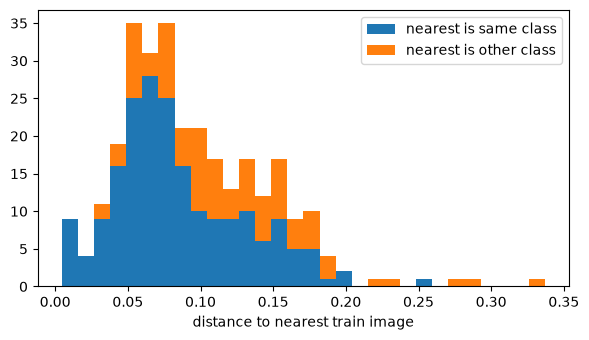

median distance | same-class NN: 0.0754 | other-class NN: 0.1101


In [2]:
nn = NearestNeighbors(n_neighbors=1).fit(H_train)
dist, idx = nn.kneighbors(H_val)
dist, idx = dist[:, 0], idx[:, 0]
same = y_train[idx] == y_val
print("1-NN accuracy on validation:", same.mean().round(4))

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.hist([dist[same], dist[~same]], bins=30, label=["nearest is same class", "nearest is other class"], stacked=True)
ax.set_xlabel("distance to nearest train image"); ax.legend(); plt.tight_layout(); plt.show()
print("median distance | same-class NN:", np.median(dist[same]).round(4), "| other-class NN:", np.median(dist[~same]).round(4))

## 2. The closest pairs (top row: validation image, bottom row: its nearest train image)

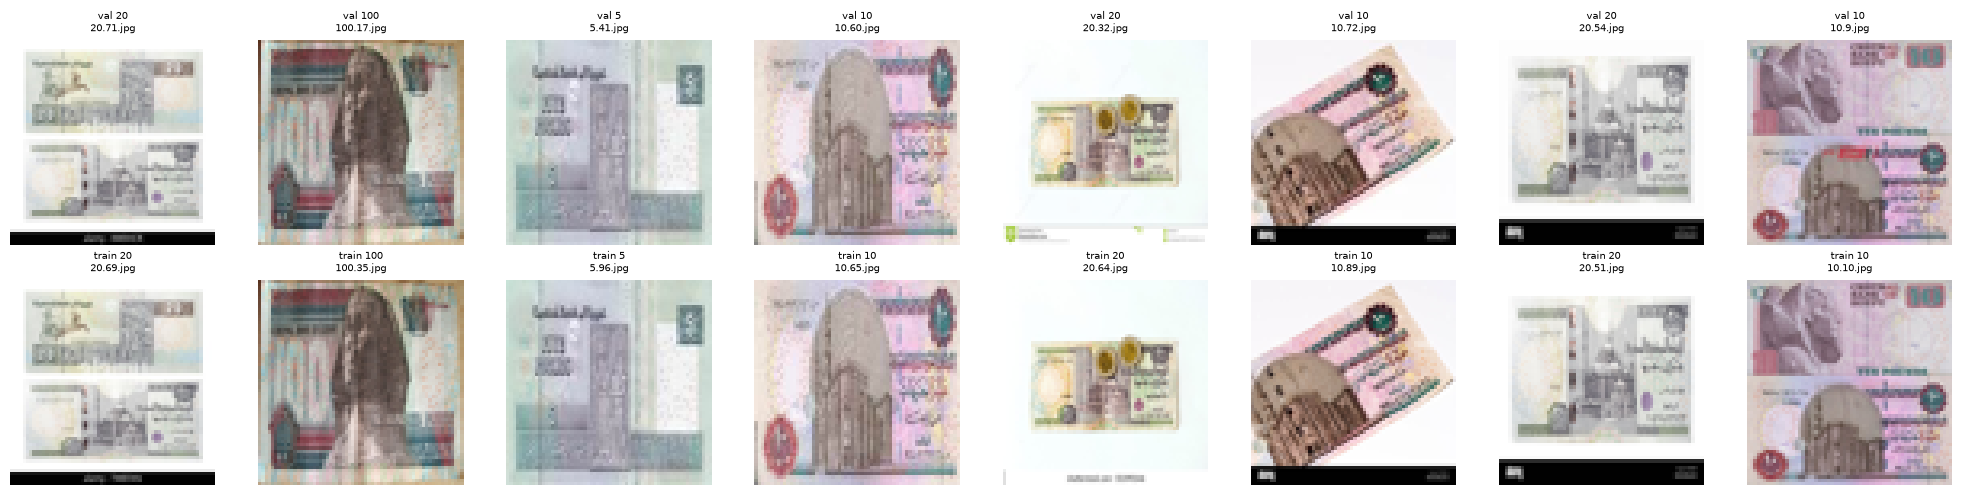

In [3]:
order = np.argsort(dist)[:8]
fig, axes = plt.subplots(2, 8, figsize=(20, 5))
for j, i in enumerate(order):
    axes[0, j].imshow(X_val[i]);          axes[0, j].set_title(f"val {CLASSES[y_val[i]]}\n{names_va[i][:22]}", fontsize=7)
    axes[1, j].imshow(X_train[idx[i]]);   axes[1, j].set_title(f"train {CLASSES[y_train[idx[i]]]}\n{names_tr[idx[i]][:22]}", fontsize=7)
    axes[0, j].axis("off"); axes[1, j].axis("off")
plt.tight_layout(); plt.show()

## 3. Capture time from the file name
Only names like `IMG_YYYYMMDD_HHMMSS` carry a time (WhatsApp files do not), so this uses the subset that has it.
For every validation photo we measure the time gap to the closest train photo **of the same class** and **of other classes**.

In [4]:
def stamp(name):
    m = re.search(r"IMG_(\d{8})_(\d{6})", name)
    return datetime.datetime.strptime(m.group(1) + m.group(2), "%Y%m%d%H%M%S").timestamp() if m else np.nan

t_tr = np.array([stamp(n) for n in names_tr]); t_va = np.array([stamp(n) for n in names_va])
print(f"names with a timestamp: train {np.mean(~np.isnan(t_tr)):.0%}, validation {np.mean(~np.isnan(t_va)):.0%}")

gap_same = np.full(len(y_val), np.nan); gap_other = np.full(len(y_val), np.nan)
for i in np.where(~np.isnan(t_va))[0]:
    ok = ~np.isnan(t_tr)
    s = ok & (y_train == y_val[i]); o = ok & (y_train != y_val[i])
    if s.any(): gap_same[i] = np.abs(t_tr[s] - t_va[i]).min()
    if o.any(): gap_other[i] = np.abs(t_tr[o] - t_va[i]).min()

has = ~np.isnan(gap_same)
rows = []
for sec, label in [(10, "10 seconds"), (60, "1 minute"), (300, "5 minutes"), (3600, "1 hour")]:
    rows.append({"closest train photo within": label,
                 "same class": np.mean(gap_same[has] <= sec).round(3),
                 "other classes": np.mean(gap_other[has] <= sec).round(3)})
print(pd.DataFrame(rows).to_string(index=False))
print("median gap in seconds | same class:", np.nanmedian(gap_same), "| other classes:", np.nanmedian(gap_other))

names with a timestamp: train 31%, validation 32%
closest train photo within  same class  other classes
                10 seconds       0.916          0.221
                  1 minute       0.989          0.421
                 5 minutes       1.000          0.611
                    1 hour       1.000          1.000
median gap in seconds | same class: 4.0 | other classes: 92.0


## 4. Does 1-NN work better when its neighbor was shot seconds earlier or later?

In [5]:
gap_nn = np.abs(t_va - t_tr[idx])
both = ~np.isnan(gap_nn)
close = both & (gap_nn <= 60); far = both & (gap_nn > 60)
def acc(mask):
    return f"{same[mask].mean():.3f}" if mask.sum() else "n/a"
print(f"1-NN accuracy | neighbor within 60 s : {acc(close)}  (n={close.sum()})")
print(f"1-NN accuracy | neighbor farther     : {acc(far)}  (n={far.sum()})")
print(f"1-NN accuracy | no timestamp         : {acc(~both)}  (n={(~both).sum()})")

1-NN accuracy | neighbor within 60 s : 1.000  (n=52)
1-NN accuracy | neighbor farther     : 0.189  (n=37)
1-NN accuracy | no timestamp         : 0.686  (n=204)
